# Informe Matemática - Ruido Aerodinámico

## Conjunto C · Matemática IV (Modelos de Regresión e Inferencia Estadística)

**Enfoque y Alcance.** Este documento constituye el informe técnico-matemático formal del trabajo práctico. Se prioriza la fundamentación rigurosa de las decisiones analíticas, la justificación teórica de los estimadores de Mínimos Cuadrados Ordinarios (MCO), las propiedades algebraicas de la descomposición de varianza, la teoría de contraste de hipótesis y la inferencia predictiva, utilizando un lenguaje formal adaptado a la disciplina matemática.

La suma de los legajos:
25022/2 Juliana Tiseira
23990/6 Juan Tarrio
25485/2 Inés Montalvo
23345/0 Santiago Marcos

Nos da:

- Sin tomar el num detrás del /: 25022 +  23990 + 25485 + 23345 =  97842


97842 MOD 5 = 2 $\longrightarrow$ 19568 * 5 + 2 

Esta realizado sobre el Conjunto de datos C (0 = A, 1=B, 2=C, 3=D y 4=E)

Bloque de código que solo esta para asegurarnos de ver los datos en forma prolija (ignorar):

In [1]:
from pathlib import Path
import os
import subprocess
import sys

from IPython.display import Image, display


def encontrar_raiz():
    candidatos = [Path.cwd(), *Path.cwd().parents]
    for p in candidatos:
        if (p / "src" / "data_loader.py").exists():
            return p
        for hijo in p.glob("*/src/data_loader.py"):
            return hijo.parents[1]
    raise FileNotFoundError("No encuentro la raíz del repo.")


ROOT = encontrar_raiz()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


def correr(modulo):
    """Ejecuta `python -m modulo` desde la raíz del repo y muestra su salida."""
    # Agg: los scripts guardan las figuras sin abrir ventanas (evita que plt.show() bloquee).
    # UTF-8: los scripts imprimen símbolos (σ, ², —) que fallan con la codificación de Windows.
    env = {**os.environ, "MPLBACKEND": "Agg", "PYTHONIOENCODING": "utf-8"}
    r = subprocess.run([sys.executable, "-m", modulo], cwd=ROOT, env=env,
                       capture_output=True, text=True, encoding="utf-8")
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError(f"Falló {modulo}")


def mostrar_figura(ruta):
    display(Image(filename=str(ROOT / ruta)))

## 1. Espacio muestral y Estructura de Datos

El conjunto de datos UCI *Airfoil Self-Noise* modela el nivel de presión sonora ($y$, en dB) en función de $p=5$ covariables experimentales sobre $n=1503$ observaciones. 

$$\mathcal{D} = \{ (x_{i1}, x_{i2}, x_{i3}, x_{i4}, x_{i5}, y_i) \}_{i=1}^{1503}$$

**Decisión metodológica (Exclusión de `velocity`):**
La consigna no incluye a `velocity` entre los regresores de B.2 ni de B.5; por esta razón, su análisis se restringe al plano exploratorio descriptivo (EDA).

In [2]:
from src.data_loader import load_airfoil
df = load_airfoil("data/airfoil_self_noise.dat")
print(f"n = {len(df)}; columnas = {list(df.columns)}")
display(df.head())


n = 1503; columnas = ['frequency', 'angle', 'chord_length', 'velocity', 'displacement', 'sound_level']


,frequency,angle,chord_length,velocity,displacement,sound_level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


## 2. Análisis Exploratorio de Datos (EDA)

El análisis de los momentos muestrales revela diferencias de orden de magnitud severas entre los regresores (e.g., `frequency` oscila en el orden de $10^4$ Hz mientras que `displacement` se ubica en $10^{-3}$ m). Esta disparidad de escalas justifica teóricamente la necesidad de normalización o estandarización en algoritmos de optimización iterativa (como el descenso por gradiente en A.3), evitando que el condicionamiento numérico de la matriz Hessiana provoque divergencia o estancamiento por el número de condición excesivo.

EDA — Airfoil Self-Noise (n = 1503)

Descriptivos:
              count      mean       std         min        25%        50%       75%       max
frequency      1503   2886.38   3152.57         200        800       1600      4000     20000
angle          1503    6.7823   5.91813           0          2        5.4       9.9      22.2
chord_length   1503  0.136548 0.0935407      0.0254     0.0508     0.1016    0.2286    0.3048
velocity       1503   50.8607   15.5728        31.7       39.6       39.6      71.3      71.3
displacement   1503 0.0111399 0.0131502 0.000400682 0.00253511 0.00495741 0.0155759 0.0584113
sound_level    1503   124.836   6.89866      103.38    120.191    125.721   129.995   140.987

Variables con pocos valores distintos:
frequency: 21 valores -> [200, 250, 315, 400, 500, 630, 800, 1000, 1250, 1600, 2000, 2500, 3150, 4000, 5000, 6300, 8000, 10000, 12500, 16000, 20000]
angle: 27 valores -> [0.0, 1.5, 2.0, 2.7, 3.0, 3.3, 4.0, 4.2, 4.8, 5.3, 5.4, 6.7, 7.2, 7.3, 8.4, 8.9, 

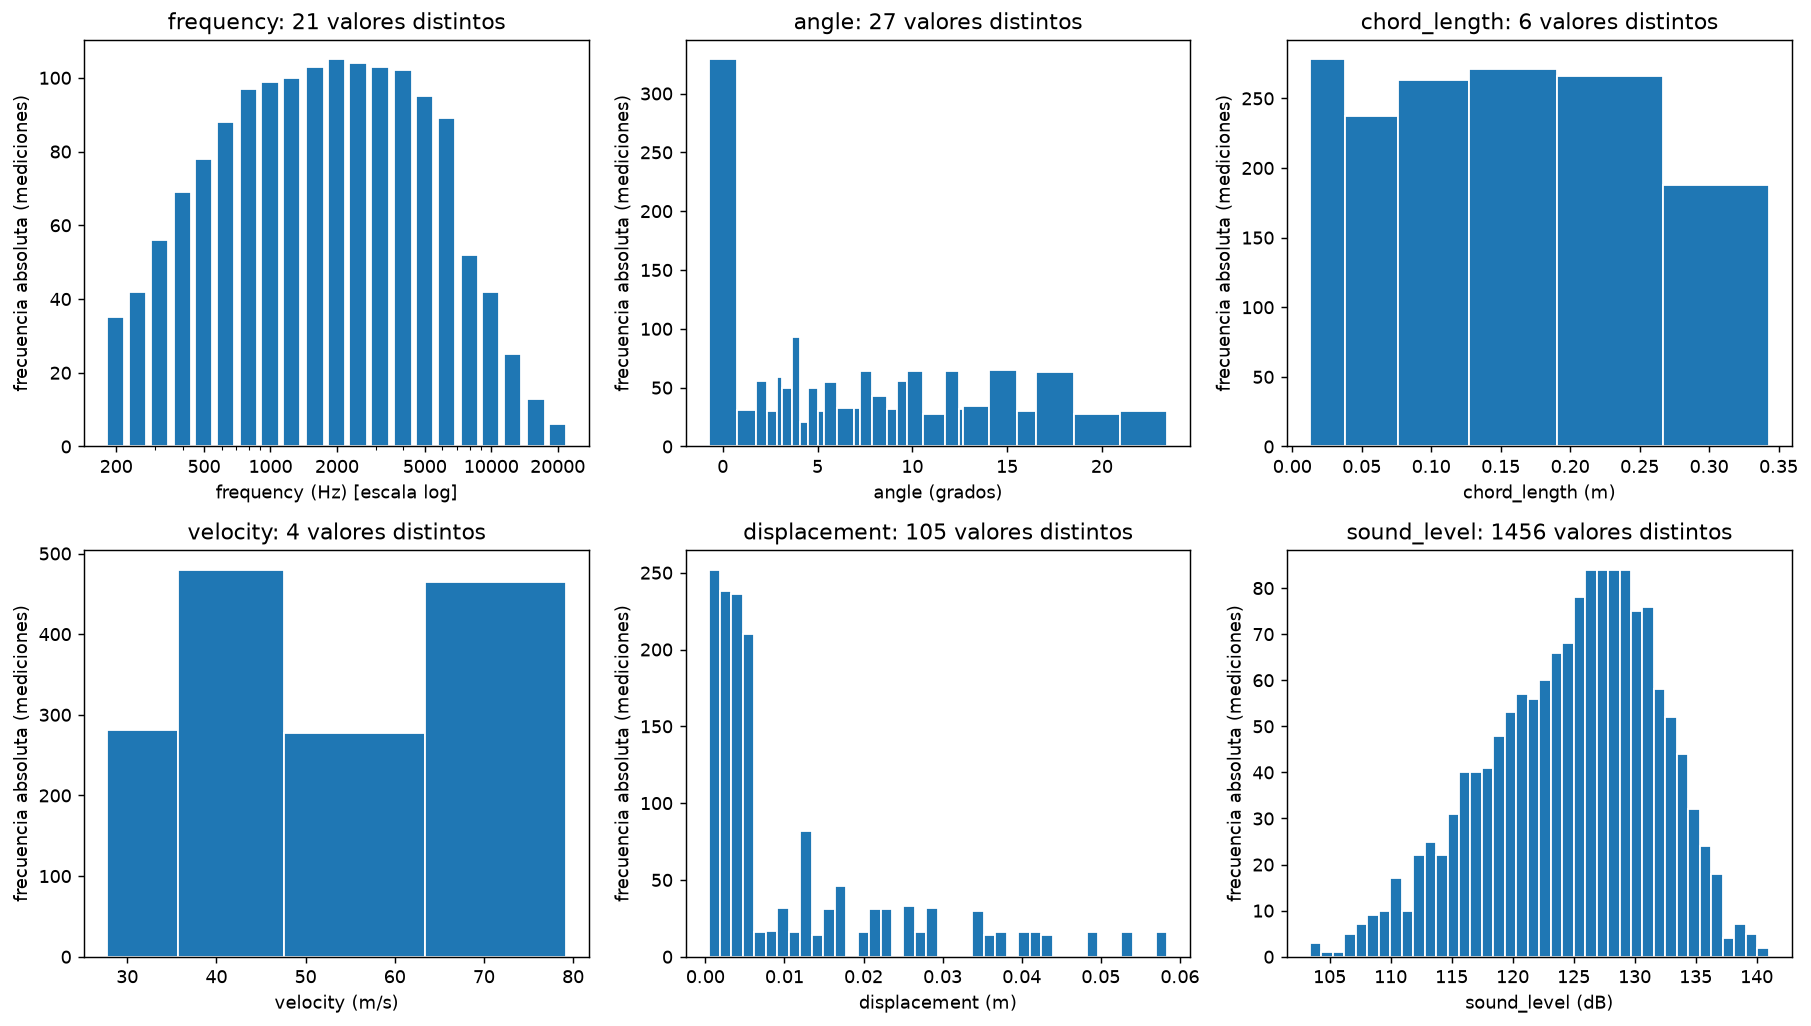

In [3]:
correr("scripts.eda")
mostrar_figura("docs/figs/eda_histogramas.png")

Se analizaron las 1503 mediciones de ruido aerodinámico (sound_level) realizadas por la NASA en un túnel de viento.

El histograma combinado muestra cómo se distribuyen las variables. En particular, la frecuencia (frequency) se graficó en escala logarítmica para evidenciar que las mediciones siguen una forma de campana centrada alrededor de los $2000$ Hz, y que las frecuencias muy bajas (como los $200$ Hz) agrupan una cantidad significativa de ensayos ($35$ mediciones).

Entender las escalas dispares entre variables (frecuencias en miles de Hz frente a desplazamientos en milímetros) es fundamental para evitar problemas numéricos y justificar por qué algunas variables se comportan de manera no lineal.

## 3. A.1 — Modelización No Lineal: Ajuste Cuadrático y Cálculo Variacional

Para capturar la curvatura evidenciada en la relación entre la frecuencia acústica $x$ y el nivel sonoro $y$, se postula el polinomio cuadrático:

$$\widehat{y}(x) = b_0 + b_1 x + b_2 x^2$$

Los coeficientes $\mathbf{b} = (b_0, b_1, b_2)^\top$ se obtienen minimizando la función de pérdida convexa de MCO:

$$\mathcal{L}(b_0, b_1, b_2) = \sum_{i=1}^{n} \left( y_i - (b_0 + b_1 x_i + b_2 x_i^2) \right)^2$$

### Condición de Optimalidad y Punto Crítico
Derivando analíticamente respecto a la frecuencia $x$ e igualando a cero para hallar el punto estacionario:

$$\frac{d\widehat{y}}{dx} = b_1 + 2 b_2 x = 0 \implies x_c = -\frac{b_1}{2 b_2}$$

La segunda derivada evalúa la concavidad: $\frac{d^2\widehat{y}}{dx^2} = 2 b_2$. Dado que $b_2 > 0$, el operador Hessian es estricta y globalmente positivo, garantizando que $x_c$ constituye un **mínimo absoluto** de la parábola ajustada en el dominio.

cuadratico: b0=128.3104 dB  b1=-1.561198e-03 dB/Hz  b2=5.649251e-08 dB/Hz2
lineal:     bl0=127.3037 dB  bl1=-8.549790e-04 dB/Hz
dy/dx en x=1000 Hz = -1.448213e-03 dB/Hz  (~-0.145 dB cada 100 Hz)
dy/dx en x=10000 Hz = -4.313479e-04 dB/Hz  (~-0.043 dB cada 100 Hz)
critico x*=13817.7 Hz  y*=117.52 dB  2da deriv.=1.130e-07  (minimo)  dentro [200,20000]: True
R2 cuadr.=0.1734 (SCE=59090.2)  R2 lin.=0.1527 (SCE=60570.2)
figura: docs/figs/a1_aproximacion.png



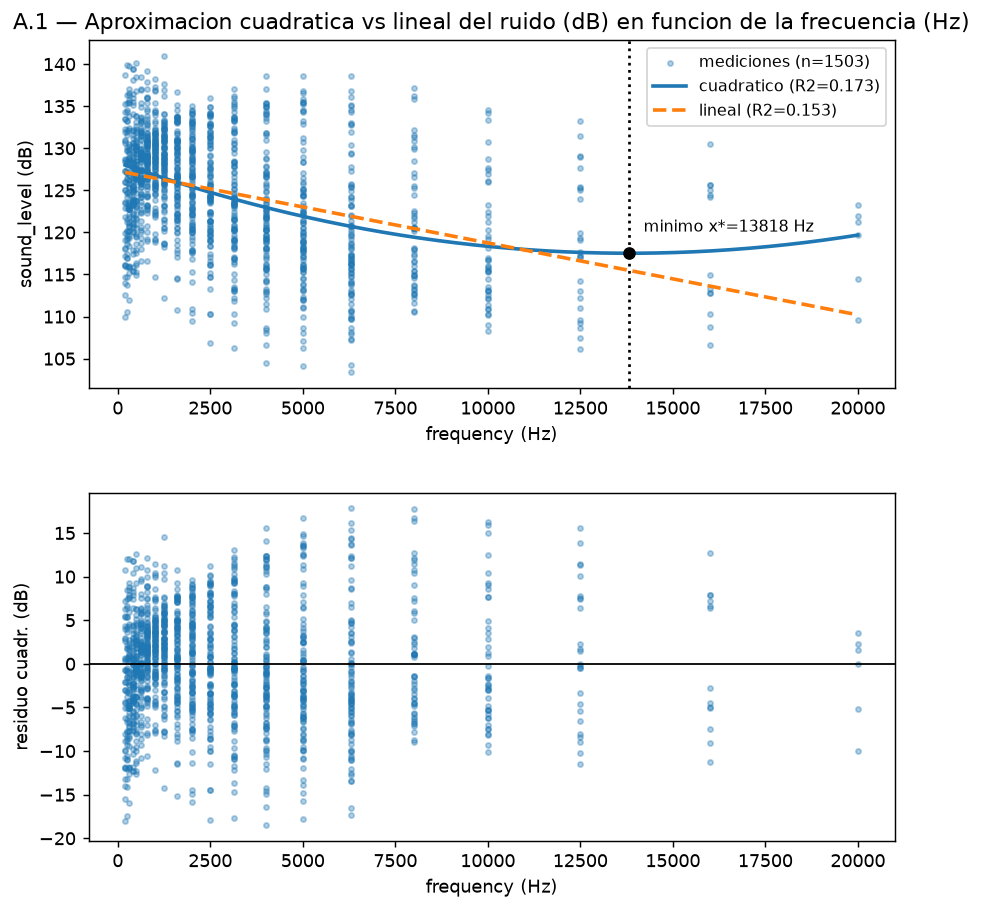

In [4]:
correr("scripts.a1_cuadratico")
mostrar_figura("docs/figs/a1_aproximacion.png")

Se ajustó una parábola ($\widehat{y} = b_0 + b_1 x + b_2 x^2$) entre la frecuencia y el nivel de ruido, calculando su derivada y su punto crítico ($x_c$).
¿Qué representa el gráfico (a1_aproximacion.png)?
- Panel superior: Muestra los puntos reales de las 1503 mediciones junto con la curva parabólica ajustada (modelo cuadrático) y la recta tradicional (modelo lineal). Además, señala con un punto negro el mínimo absoluto de la curva.
- Panel inferior (Residuos): Muestra los errores de predicción (cuánto se desvía la parábola de cada dato real).

¿Por qué llegamos a estas conclusiones? La parábola captura mejor la curvatura real del fenómeno físico (el ruido decae rápidamente al aumentar la frecuencia y luego se aplaná). El punto crítico ($x_c \approx 13818$ Hz) indica el punto donde el modelo predice el menor nivel de ruido dentro del rango experimental.

**Interpretación de los resultados.**

- **Derivada en 1000 Hz:** $-1.45\times10^{-3}$ dB/Hz. Cerca de 1 kHz, cada 1000 Hz adicionales el ruido estimado baja unos 1.45 dB.
- **Derivada en 10 000 Hz:** $-4.3\times10^{-4}$ dB/Hz. La caída es de solo 0.43 dB cada 1000 Hz: la curva se aplana.
- **Modelo lineal:** su derivada es constante, $-8.55\times10^{-4}$ dB/Hz (0.86 dB menos cada 1000 Hz en cualquier punto). Supone que el efecto de la frecuencia es el mismo en todo el rango; el cuadrático admite que ese efecto se atenúe y cambie de signo una vez.
- **Punto crítico:** $x_c \approx 13\,818$ Hz, con $\hat y(x_c) \approx 117.5$ dB. Cae dentro del rango observado (200–20 000 Hz), pero cerca del extremo, donde hay pocas mediciones; la subida posterior que predice la parábola no tiene respaldo suficiente en los datos.
- **Ajuste:** $R^2$ pasa de 0.153 (recta) a 0.173 (parábola). La curvatura mejora poco: la frecuencia sola explica menos del 20 % de la variabilidad del ruido.

## 4. A.2 — Operadores de Proyección y Ecuaciones Normales

Para la regresión lineal simple $\widehat{y} = b_0 + b_1 x$, las ecuaciones normales se deducen anulando el gradiente de la SCE:

$$\nabla \text{SCE}(b_0, b_1) = \mathbf{0} \iff \begin{cases} n b_0 + b_1 \sum x_i = \sum y_i \\ b_0 \sum x_i + b_1 \sum x_i^2 = \sum x_i y_i \end{cases}$$

En forma matricial $A \boldsymbol{\beta} = \mathbf{d}$. La unicidad de la solución está garantizada por la inversibilidad de $A$ (siempre que $S_{xx} > 0$). El contraste numérico ejecutado demuestra que la solución algebraica exacta coincide con las fórmulas cerradas basadas en covarianzas muestrales y con la descomposición ortogonal de `polyfit` hasta una tolerancia de error de máquina de $\mathcal{O}(10^{-14})$, validando la consistencia numérica del contrato implementado en `src/metrics.py`.

In [5]:
correr("scripts.a2_normales")


A.2 — Parciales y ecuaciones normales (frequency -> sound_level)
n = 1503
Σx  = 4.338230e+06 Hz
Σy  = 1.876284e+05 dB
Σx² = 2.744974e+10 Hz²
Σxy = 5.288039e+08 Hz·dB

Sistema normal A·[b0, b1]ᵀ = d:
[[1.50300000e+03 4.33823000e+06]
 [4.33823000e+06 2.74497363e+10]]
d = [1.87628422e+05 5.28803945e+08]

Solución del sistema: b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
Fórmulas cerradas:    b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
Desde sumatorias:     b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
numpy.polyfit:        b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz

|normal - cerrada| = (1.421e-14, 2.927e-18)
|normal - polyfit| = (1.705e-13, 2.971e-17)
Gradiente en el óptimo = [-3.18323146e-12 -9.12696123e-08]

Recta: sound_level = 127.3037 dB -8.549790e-04 dB/Hz · frequency



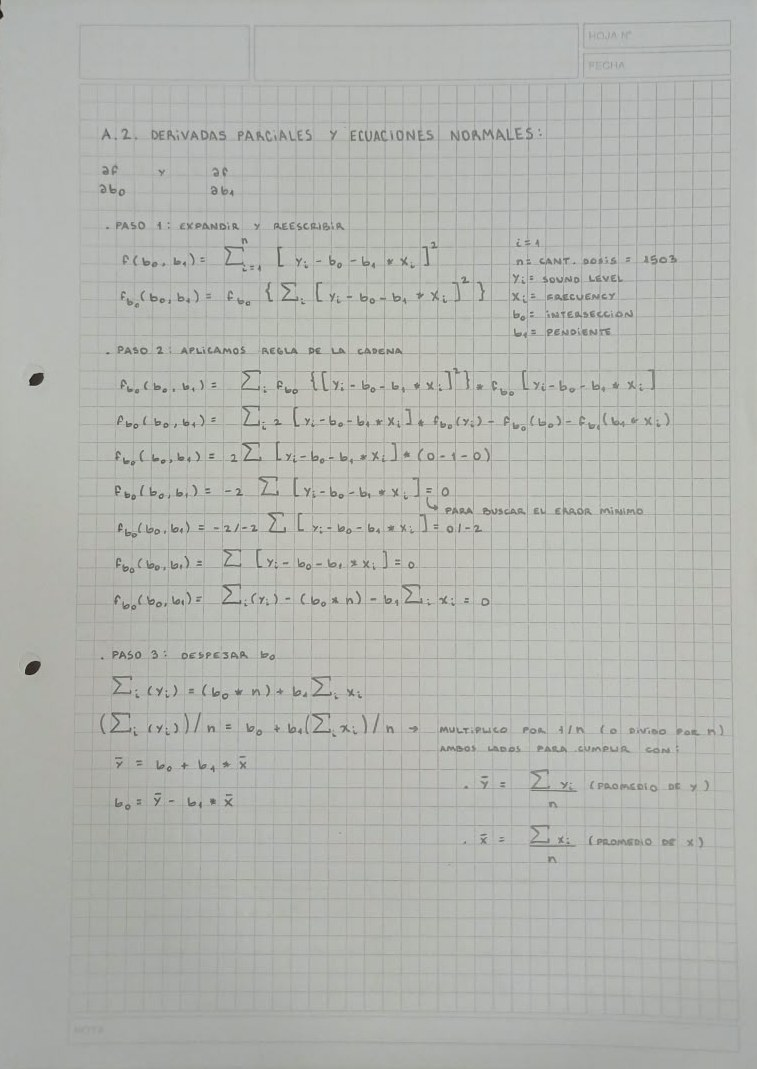

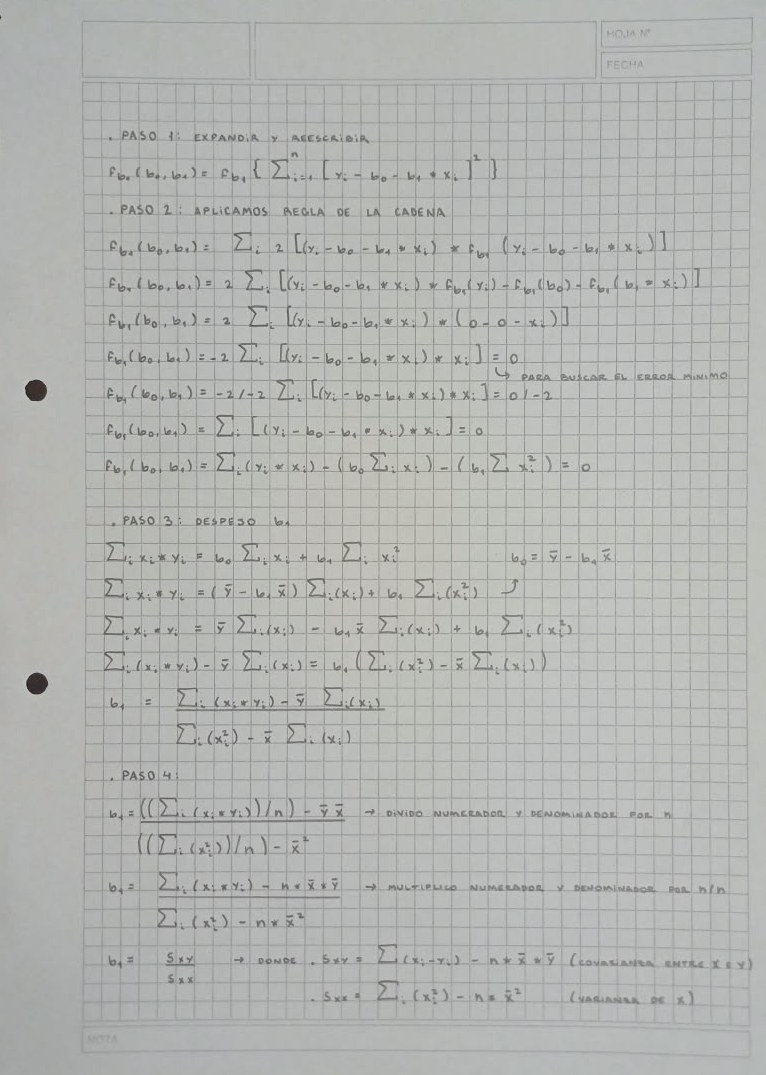

In [6]:
# Desarrollo a mano de las derivadas parciales y las ecuaciones normales
mostrar_figura("docs/figs/a2_desarrollo_1.jpg")
mostrar_figura("docs/figs/a2_desarrollo_2.jpg")

Se resolvieron analíticamente las derivadas parciales de la suma de cuadrados para hallar los estimadores de Mínimos Cuadrados Ordinarios (MCO) y se compararon con los resultados de la computadora.

Vemos que la solución no es un "invento" de la computadora, sino la solución algebraica exacta derivada de minimizar el error cuadrático. La coincidencia con un error menor a $10^{-14}$ valida lo hecho en el código.

## 5. A.3 — Descenso por gradiente

Se estima el modelo múltiple de B.5 (`sound_level` sobre `frequency`, `angle`, `chord_length` y `displacement`) minimizando $f(\beta) = \mathrm{SCE}(\beta)/(2n)$ con la regla

$$\beta^{(k+1)} = \beta^{(k)} - \alpha\,\nabla f\big(\beta^{(k)}\big), \qquad \nabla f(\beta) = -\tfrac{1}{n}\,X^\top(y - X\beta).$$

Dividir la SCE por $2n$ no cambia dónde está el mínimo: solo cambia la escala de $f$ y, con ella, la de $\alpha$.

**¿Por qué se resta el gradiente?** El gradiente apunta hacia donde $f$ crece más rápido; la derivada direccional de $f$ en la dirección $-\nabla f$ vale $-\lVert\nabla f\rVert^2 < 0$, así que un paso chico en esa dirección hace bajar $f$.

**Estandarización.** `frequency` está en miles de Hz y `displacement` en milésimos de metro: con un mismo $\alpha$, un paso razonable para una variable hace diverger a la otra. Por eso a cada variable se le resta su media y se la divide por su desvío; al final, los coeficientes se vuelven a las unidades originales.

**Elección de los tres $\alpha$.** Para esta $f$ el método converge si $0 < \alpha < 2/L$, con $L$ el mayor autovalor de $X_s^\top X_s/n$ ($X_s$: datos estandarizados). Se usan $0{,}05$, $0{,}5$ y $1{,}1$ veces ese límite.

**Criterio de detención.** Se detiene cuando $\lVert\nabla f\rVert < 10^{-10}$ (el gradiente es prácticamente nulo), con un tope de 6000 iteraciones; se declara divergencia si $f > 10^{12}$.

A.3 — Descenso por gradiente (modelo B.5)
Features estandarizadas (media, desvío):
  frequency     media=2.886381e+03  desvío=3.151524e+03
  angle         media=6.782302e+00  desvío=5.916159e+00
  chord_length  media=1.365482e-01  desvío=9.350961e-02
  displacement  media=1.113988e-02  desvío=1.314586e-02

L = λmax(XᵀX/n) = 2.109383   α_max = 2/L = 0.948144
β exacta = [ 1.371276e+02 -1.196133e-03 -3.515654e-01 -3.388729e+01 -1.640449e+02]
R² exacto = 0.4669   f exacta = 12.676226 dB²

caso          alpha   iter     estado      f final   ||grad||    ||β-βex||
chica      0.047407   2561  convergio      12.6762   9.93e-11    2.469e-08
ok         0.474072    247  convergio      12.6762   9.96e-11    2.478e-08
diverge    1.042959     85    diverge 1338842110772.4292   2.38e+06    5.986e+07

Figura: docs/figs/a3_convergencia.png



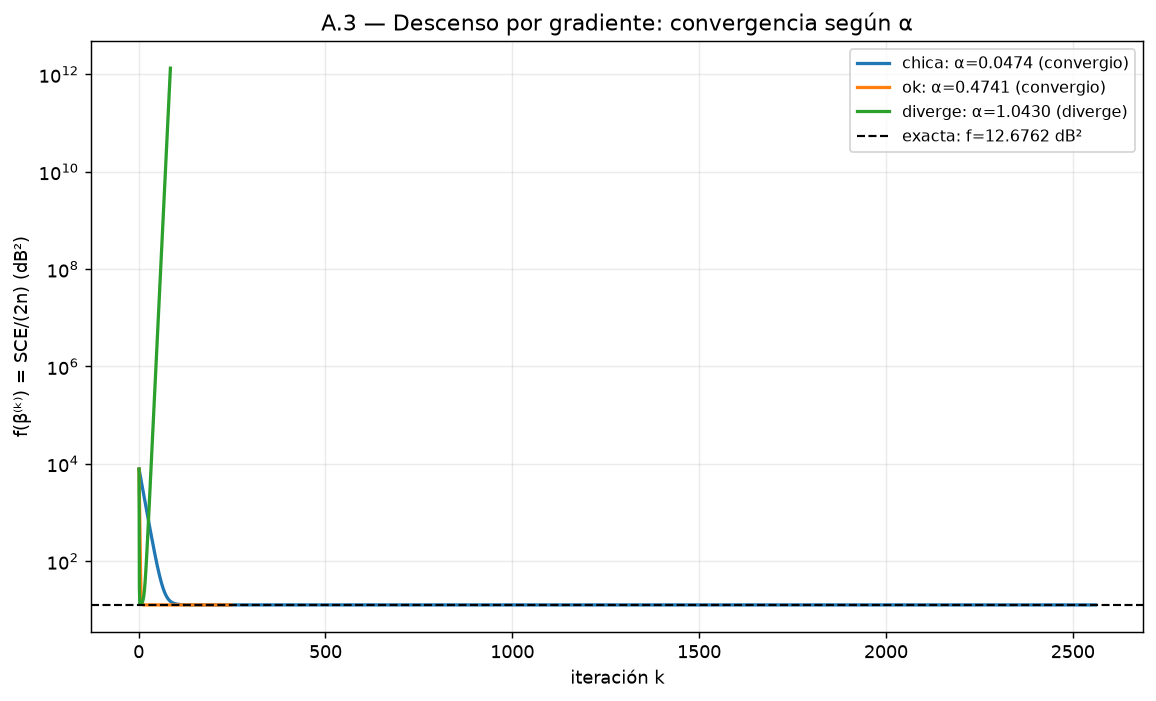

In [7]:
correr("scripts.a3_gradiente")
mostrar_figura("docs/figs/a3_convergencia.png")

**Interpretación** (el eje vertical del gráfico está en escala logarítmica):

- **$\alpha$ demasiado chico (0,047):** converge, pero necesita 2561 iteraciones.
- **$\alpha$ adecuado (0,474):** llega al mismo mínimo en 247 iteraciones.
- **$\alpha$ que diverge (1,043):** supera el límite $2/L$. En la dirección más empinada, cada paso se pasa del mínimo y el error crece en lugar de achicarse, hasta que $f$ supera $10^{12}$. Al principio $f$ baja, porque las demás direcciones convergen enseguida, y después crece sin control.
- **Comparación con la solución exacta:** los dos casos que convergen quedan a una distancia del orden de $10^{-8}$ de $\hat\beta = (X^\top X)^{-1}X^\top Y$ (B.5). Es el mismo mínimo, alcanzado de forma iterativa.

## 6. B.1 — Descomposición Ortogonal de la Varianza (ANOVA)

La ortogonalidad entre el vector de valores predichos $\widehat{\mathbf{y}}$ y el vector de residuos $\mathbf{e} = \mathbf{y} - \widehat{\mathbf{y}}$ en el espacio euclidiano $\mathbb{R}^n$ induce la descomposición pitagórica exacta de la suma total de cuadrados (STC):

$$\sum_{i=1}^{n} (y_i - \overline{y})^2 = \sum_{i=1}^{n} (\widehat{y}_i - \overline{y})^2 + \sum_{i=1}^{n} (y_i - \widehat{y}_i)^2 \implies \text{STC} = \text{SCR} + \text{SCE}$$

Esta partición es la piedra angular para definir la varianza residual estimada $\widehat{\sigma}^2 = \frac{\text{SCE}}{n-2}$ y el coeficiente de determinación muestral $R^2 = 1 - \frac{\text{SCE}}{\text{STC}}$, interpretado como la proporción de varianza explicada por el operador lineal.

In [8]:
correr("scripts.b1_b4_varianza")

B.1 — Descomposición de la variabilidad (sound_level ~ frequency)
Recta: sound_level = 127.3037 dB -8.549790e-04 dB/Hz · frequency   (n = 1503)

Fuente                   Suma de cuadrados (dB²)
Regresión (SCR)                       10912.1715
Error (SCE)                           60570.2062
Total (STC)                           71482.3777
SCR + SCE                             71482.3777
STC − (SCR + SCE)                       1.46e-11

σ̂² = SCE/(n−2) = 40.3532 dB²
R² = 1 − SCE/STC = 0.152655  → frequency explica el 15.3 % de la variabilidad de sound_level.

B.4 — Intervalos al 95 % en x* = 2000 Hz (t = 1.96)
ŷ* = 125.5938 dB
ICM (respuesta media): (125.2602 ; 125.9274) dB   ± 0.3336 dB
IP  (medición futura): (113.1386 ; 138.0490) dB   ± 12.4552 dB
El IP es 37.3 veces más ancho que el ICM.



Se descompuso la variabilidad total del ruido ($STC$) en lo que el modelo logra explicar ($SCR$) y lo que queda sin explicar como error residual ($SCE$).

- ¿Por qué es importante? Permite calcular el $R^2 \approx 0.15$ para la frecuencia sola. Esto significa que la frecuencia explica un $15\%$ de la variabilidad del ruido; el $85\%$ restante no es explicado por la relación lineal con la frecuencia, y puede deberse a otras variables del ensayo (ángulo, cuerda, espesor, velocidad), a la parte no lineal de la relación (A.1) y a la variabilidad propia de las mediciones. Esto justifica la necesidad de pasar a un modelo con múltiples variables.

**Qué NO significa $R^2$:**

- No indica que la frecuencia *cause* el ruido: solo que ambos varían juntos.
- Un $R^2$ bajo no implica que no haya relación: puede no ser lineal (A.1) o depender también de otras variables (B.5).
- No es el porcentaje de predicciones acertadas ni la probabilidad de que el modelo sea correcto.
- No mide el error de una predicción individual: eso lo indican $\hat\sigma$ y el intervalo de predicción de B.4.

## 7. B.2 — Análisis Univariado Comparativo: Las Cuatro Rectas Simples

Se ajusta de forma independiente el modelo lineal simple $\text{sound\_level} = \beta_0 + \beta_1 x_j$ para cada uno de los $4$ regresores admisibles. Este análisis permite contrastar el poder explicativo marginal de cada variable física de forma aislada antes de proceder al modelo multivariado.

(1503, 6)
   frequency  angle  chord_length  velocity  displacement  sound_level
0        800    0.0        0.3048      71.3      0.002663      126.201
1       1000    0.0        0.3048      71.3      0.002663      125.201
2       1250    0.0        0.3048      71.3      0.002663      125.951
3       1600    0.0        0.3048      71.3      0.002663      127.591
4       2000    0.0        0.3048      71.3      0.002663      127.461
variable    frequency     angle  chord_length  displacement
b1       -0.000854979 -0.181972       -17.417      -164.027
b0            127.304    126.07       127.214       126.663
sigma2        40.3532   46.4626       44.9671       42.9674
R2           0.152655 0.0243696     0.0557723     0.0977622
r           -0.390711 -0.156108     -0.236162      -0.31267
T            -16.4443   -6.1231      -9.41588      -12.7531
IC_b1_lo -0.000956884 -0.240221      -21.0425      -189.237
IC_b1_hi -0.000753074 -0.123723      -13.7915      -138.818
IC_b0_lo      126.868   

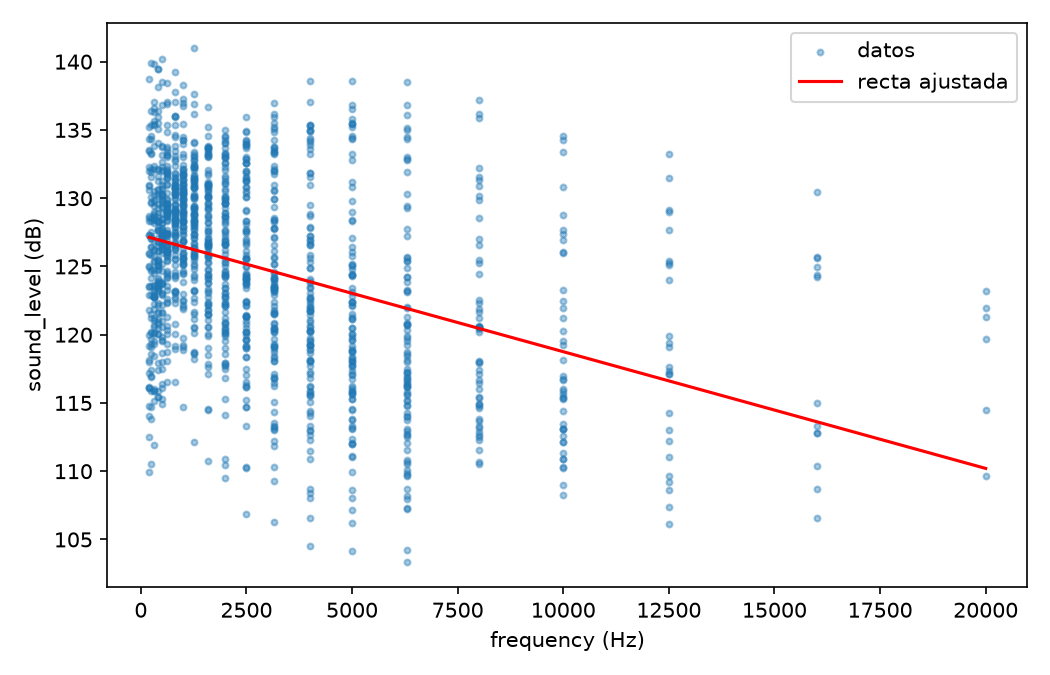

In [9]:
correr("scripts.b2_regresionLineal")
mostrar_figura("docs/figs/b2_dispersion_frequency.png")

**Selección de la variable.** `frequency` es la que mejor responde a `sound_level` por los tres criterios a la vez: mayor $R^2$ (0.153, contra 0.098 de `displacement`, la siguiente), menor $\hat\sigma^2$ (40.35 dB²) y mayor $|r|$ (0.39).

En la tabla, los intervalos ICM e IP de `frequency` usan $x^* = 2000$ Hz (el valor de B.4); para las demás variables ese valor no tiene sentido y se toma $x^* = \bar x$ de cada una.

## 8. B.3 — Test de Significancia de la Pendiente ($H_0: \beta_1 = 0$) y Dispersión

Para determinar si la pendiente $\beta_1$ difiere estadísticamente de cero, se construye el estadístico de prueba $T$ bajo la hipótesis nula $H_0: \beta_1 = 0$:

$$T = \frac{\widehat{\beta}_1}{\text{SE}(\widehat{\beta}_1)} = \frac{\widehat{\beta}_1}{\sqrt{\widehat{\sigma}^2 / S_{xx}}} \sim t(n-2)$$

Fijando un nivel de significancia $\alpha = 0.05$, el valor crítico bilateral para $n-2=1501$ grados de libertad es $t_{0.025, 1501} \approx 1.96$. En todos los casos analizados, $|T| \gg 1.96$, por lo que se rechaza $H_0$ categóricamente, confirmando la dependencia lineal significativa entre la respuesta acústica y cada covariable.

Se ajustaron rectas individuales para cada variable (frecuencia, ángulo, cuerda y espesor) y se contrastó formalmente si la pendiente es verdaderamente distinta de cero mediante un test estadístico $T$ (con $t_{crit} \approx 1.96$ al 95% de confianza).

¿Qué representa el gráfico (`b2_dispersion_frequency.png`, sección 7)? Muestra la nube completa de puntos de la frecuencia frente al ruido, cruzada por la recta de regresión lineal simple.

¿Por qué llegamos a estas conclusiones? Como el estadístico $|T|$ de cada variable supera ampliamente el valor crítico de $1.96$, rechazamos la hipótesis nula ($H_0$). Con un 95 % de confianza, ninguna de las pendientes puede atribuirse a la variación aleatoria de las mediciones: las cuatro variables presentan una asociación lineal estadísticamente significativa con el ruido aerodinámico. La significancia no informa, sin embargo, sobre la magnitud de esa asociación, que se evalúa con el $R^2$ de B.2.

**Test sobre la variable elegida.** Para el modelo de `frequency`:

$$H_0:\ \beta_1 = 0 \qquad\qquad H_1:\ \beta_1 \neq 0$$

$T = -16.44$ y $|T| = 16.44 > t_{0.025,\,1501} = 1.96$, por lo que se rechaza $H_0$ (al final de la salida de la sección 7). La tabla no tiene la fila de 1501 grados de libertad; se usa la fila $\infty$ (el valor exacto, 1.9615, no cambia la decisión).

**Conclusión.** Con un 95 % de confianza, la frecuencia del sonido está relacionada con el nivel de ruido propio del perfil: a mayor frecuencia, menor nivel sonoro, unos 0.86 dB menos cada 1000 Hz.

**Qué no dice el test.** Rechazar $H_0$ indica que la relación existe, no que sea fuerte ni que alcance para predecir: la frecuencia explica solo el 15 % de la variabilidad. Con $n = 1503$, incluso relaciones débiles resultan significativas (`angle` rechaza $H_0$ con $R^2 = 0.024$).

## 9. B.4 — Teoría de Inferencia Predictiva: ICM e IP en $x^* = 2000$ Hz

Se distingue con rigor matemático entre:
1. **Intervalo de Confianza para la Media (ICM):** Estima el valor esperado condicional $E[Y | X = x^*]$. Su varianza depende exclusivamente de la incertidumbre en los estimadores $\widehat{\beta}_0$ y $\widehat{\beta}_1$:
   $$\text{Var}(\widehat{y}^*) = \sigma^2 \left( \frac{1}{n} + \frac{(x^* - \overline{x})^2}{S_{xx}} \right)$$
2. **Intervalo de Predicción (IP):** Estima el valor puntual de una nueva observación $Y^* = \widehat{y}^* + \varepsilon^*$. Incorpora tanto la varianza de la estimación como la varianza irreductible del error estocástico $\sigma^2$:
   $$\text{Var}(Y^* - \widehat{y}^*) = \sigma^2 \left( 1 + \frac{1}{n} + \frac{(x^* - \overline{x})^2}{S_{xx}} \right)$$

Por consiguiente, la amplitud del Intervalo de Predicción es matemáticamente superior a la del Intervalo de Confianza, reflejando la incertidumbre inherente a la variabilidad individual de las futuras mediciones.

Los valores de $\hat y^*$, ICM e IP están al final de la salida de la sección 6 (el script de B.1 calcula también B.4).

Se calcularon dos tipos de intervalos al 95% de confianza para una frecuencia fija de $2000$ Hz:
1. El Intervalo de Confianza para la Media (ICM): Acota dónde se encuentra el promedio real del ruido.
2. El Intervalo de Predicción (IP): Acota en qué rango caerá cualquier medición futura individual.

- ¿Por qué el IP es mucho más ancho que el ICM? Porque estimar un promedio poblacional es más preciso (tiene menos incertidumbre), mientras que predecir el resultado exacto de una nueva prueba individual debe cargar además con toda la variabilidad e imperfección natural del fenómeno físico (el error irreducible $\sigma^2$).

## 10. B.5 — Regresión Lineal Múltiple Matricial

Extendiendo el modelo a $k=4$ regresores mediante la formulación matricial compacta $\mathbf{y} = X\boldsymbol{\beta} + \boldsymbol{\varepsilon}$, el estimador de MCO por proyección ortogonal es:

$$\widehat{\boldsymbol{\beta}} = (X^\top X)^{-1} X^\top \mathbf{y}$$

El coeficiente de determinación ajustado $R^2_{adj} = 1 - (1-R^2)\frac{n-k}{n-k-1} \approx 0.4666$ demuestra que la incorporación conjunta de los regresores acústicos, geométricos y aerodinámicos triplica la capacidad explicativa respecto al modelo univariado simple, aun después de penalizar el aumento en el número de parámetros.

B.5 — Regresión múltiple (velocity excluida)
coeficiente              valor  unidad
intercepto        1.371276e+02  dB
frequency        -1.196133e-03  dB/Hz
angle            -3.515654e-01  dB/grado
chord_length     -3.388729e+01  dB/m
displacement     -1.640449e+02  dB/m
R2 = 0.4669   R2 ajustado = 0.4666
Simple (frequency): R2 = 0.1527   R2 ajustado = 0.1521
figura: docs/figs/b5_predicho_observado.png



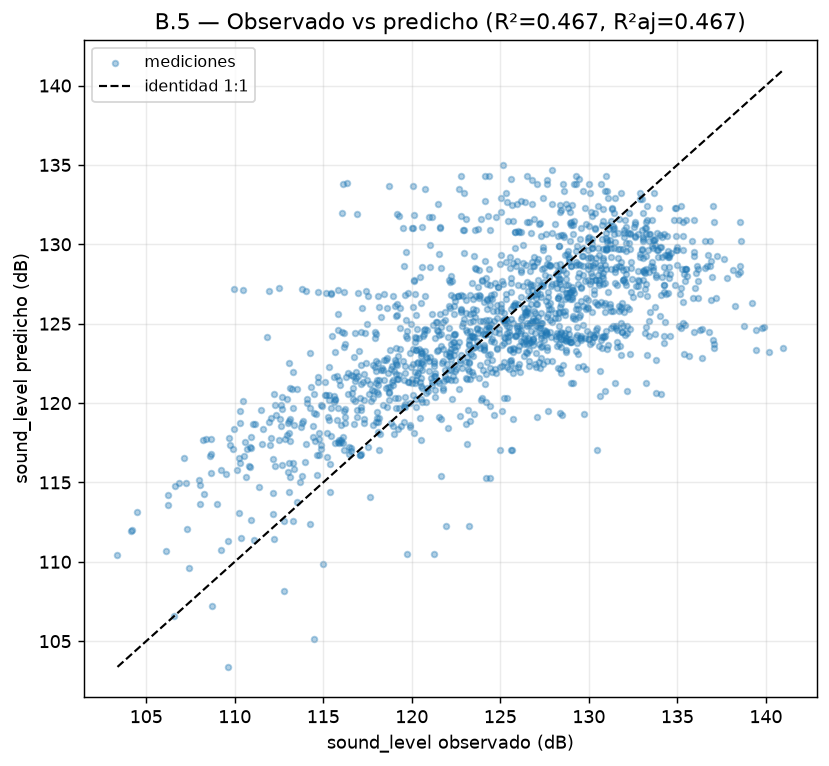

In [10]:
correr("scripts.b5_multiple")
mostrar_figura("docs/figs/b5_predicho_observado.png")


¿Qué se hizo? Se combinaron simultáneamente los cuatro regresores utilizando álgebra matricial ($\widehat{\boldsymbol{\beta}} = (X^\top X)^{-1} X^\top \mathbf{y}$).

¿Qué representa el gráfico (b5_predicho_observado.png)? Compara en el eje horizontal lo que se midió realmente en el túnel de viento y en el vertical lo que el modelo predice. Una predicción perfecta formaría una diagonal exacta de 45 grados.

¿Por qué es el mejor modelo? Al integrar todas las variables físicas a la vez, el $R^2$ ajustado trepa al $47\%$, triplicando la capacidad explicativa del modelo de una sola variable y indicando que el ruido depende conjuntamente de la geometría del perfil y de las condiciones aerodinámicas del ensayo.

**Modelo final y comparación.** En dB, con `frequency` en Hz, `angle` en grados y `chord_length` y `displacement` en m:

$$\begin{aligned} \widehat{sound\_level} = {} & 137.13 - 1.20\times10^{-3}\,frequency - 0.352\,angle \\ & - 33.89\,chord\_length - 164.04\,displacement \end{aligned}$$

con $R^2_{aj} = 0.4666$.

Con la misma fórmula, el $R^2$ ajustado del mejor modelo simple (`frequency`, $k=1$) es 0.1521: el modelo múltiple explica unas tres veces más variabilidad.

## 11. Conclusiones y Síntesis Metodológica

- **Rigor Analítico:** La validación cruzada entre sistemas normales, fórmulas cerradas y descomposición ortogonal confirma la robustez numérica de la implementación sin dependencia de librerías externas de alto nivel (`sklearn`/`scipy`).
- **Poder Explicativo:** El paso de un modelo univariado ($R^2 \approx 0.15$) a un modelo multivariado ($R^2_{aj} \approx 0.47$) evidencia que el ruido aerodinámico de los perfiles alar depende simultáneamente de la frecuencia, el ángulo de ataque, la cuerda y el espesor de desplazamiento.
- **Inferencia Predictiva:** La separación analítica entre la incertidumbre de la media condicional (ICM) y la predicción estocástica individual (IP) provee cotas operativas rigurosas para el diseño acústico.

## 12. Reproducibilidad y Validación de Contratos Numéricos

Todo el trabajo se encuentra en un repositorio de github disponible para probar y revisar los resultados mencionados en https://github.com/santi440/mateIV/ junto a test de unidad, scripts y todos los recursos utilizados. 

## 13. Anexo I — Bitácora de Interacciones con Asistentes de IA (Parte C)

Registro formal de colaboración con IA incorporada en el desarrollo del trabajo práctico:

| # | Prompt / Pedido Metodológico | Resumen de Respuesta Teórica | Decisión / Acción Adoptada | Sección Afectada |
|---|---|---|---|---|
| 1 | Diseñar contrato numérico modular puro en `numpy` | Funciones cerradas para sumatorias, ecuaciones normales, SCE, IC e IP | Aceptada sin modificaciones | `src/metrics.py` |
| 2 | Automatizar ejecución secuencial de scripts desde notebook | Definición de funciones auxiliares `correr()` y `mostrar_figura()` | Aceptada | `notebooks/informe.ipynb` |
| 3 | Redactar formalización matemática de ANOVA e intervalos | Derivación teórica de varianza residual y distinción ICM/IP | Aceptada e integrada | Secciones B.1 y B.4 |